# Ranking concentration through partial sums

## Ordered Partial Sums

Let $x_{[1]}\geq\cdots\geq x_{[n]}$ and $y_{[1]}\geq\cdots\geq y_{[n]}$ denote the components of two vectors after sorting from largest to smallest. We say that $y$ is majorized by $x$ when

$$
\sum_{i=1}^{k}y_{[i]}\leq\sum_{i=1}^{k}x_{[i]},\qquad k=1,\ldots,n-1,
$$

and their totals agree:

$$
\sum_{i=1}^{n}y_i=\sum_{i=1}^{n}x_i.
$$

Here, $n$ is the vector length, $k$ is a proper partial sum position, and the brackets indicate ordered components rather than time. The relation compares concentration without depending on the original component labels.

Row,Symbol,Description
,String,String
1,x,Source vector whose concentration is the reference
2,y,Target vector being compared with the source
3,x_[i],Component i after sorting x from largest to smallest
4,k,Proper partial sum position
5,D,Doubly stochastic matrix when y equals D times x


Row,Vector,Component 1,Component 2,Component 3,Component 4,Total
,String,Float64,Float64,Float64,Float64,Float64
1,Equal,0.25,0.25,0.25,0.25,1.0
2,Intermediate,0.4,0.3,0.2,0.1,1.0
3,Concentrated,0.55,0.25,0.15,0.05,1.0


Row,Position,Equal,Intermediate,Concentrated
,Int64,Float64,Float64,Float64
1,1,0.25,0.4,0.55
2,2,0.5,0.7,0.8
3,3,0.75,0.9,0.95
4,4,1.0,1.0,1.0


Row,Target,Source,Target majorized by source
,String,String,Bool
1,Equal,Equal,true
2,Equal,Intermediate,true
3,Equal,Concentrated,true
4,Intermediate,Equal,false
5,Intermediate,Intermediate,true
6,Intermediate,Concentrated,true
7,Concentrated,Equal,false
8,Concentrated,Intermediate,false
9,Concentrated,Concentrated,true


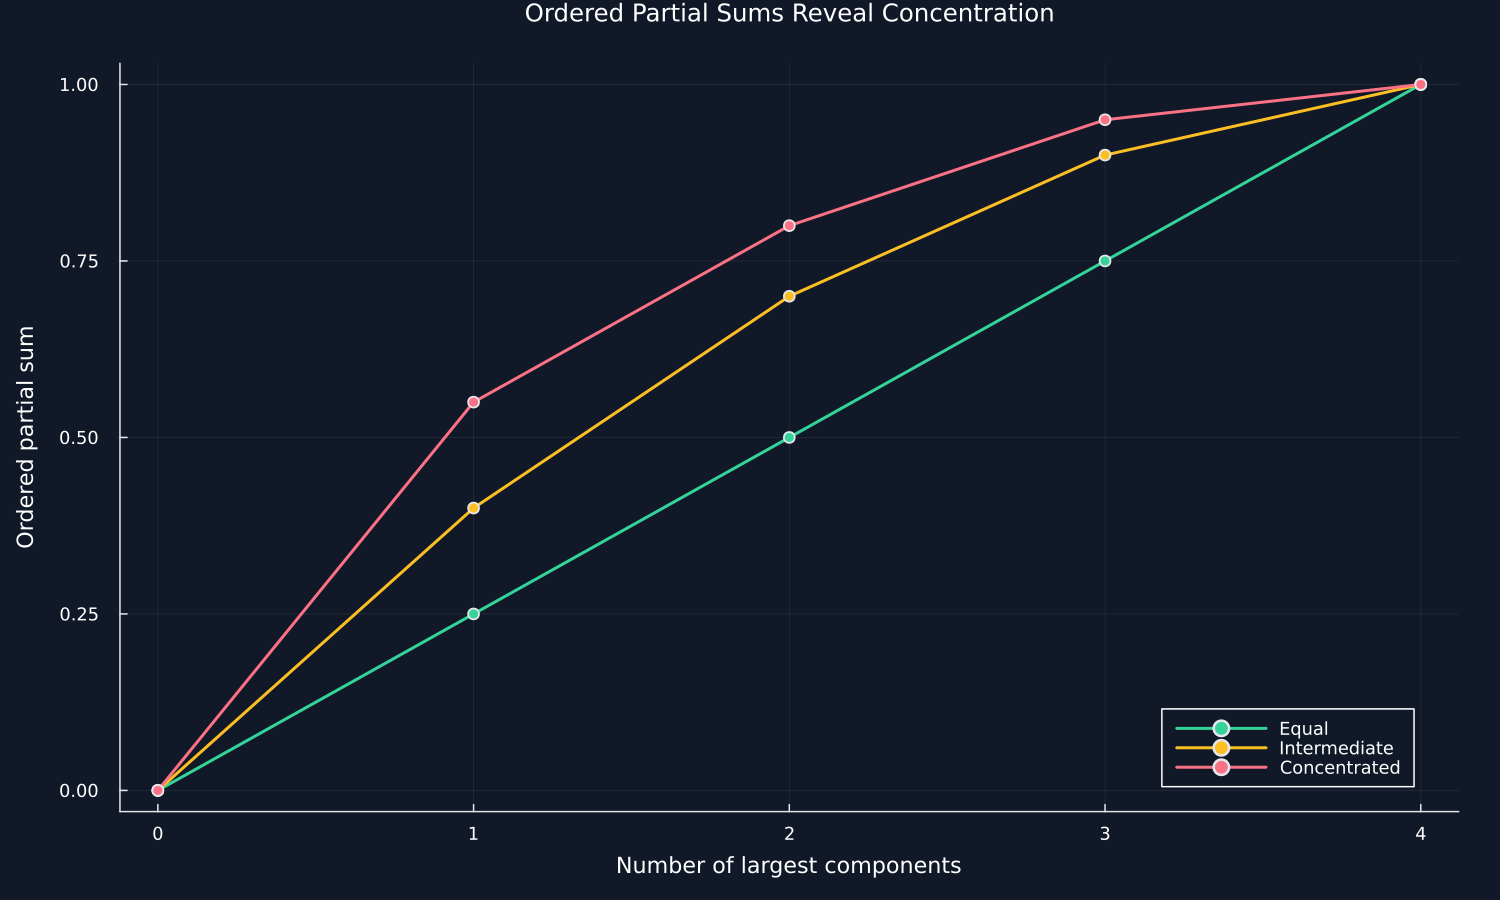

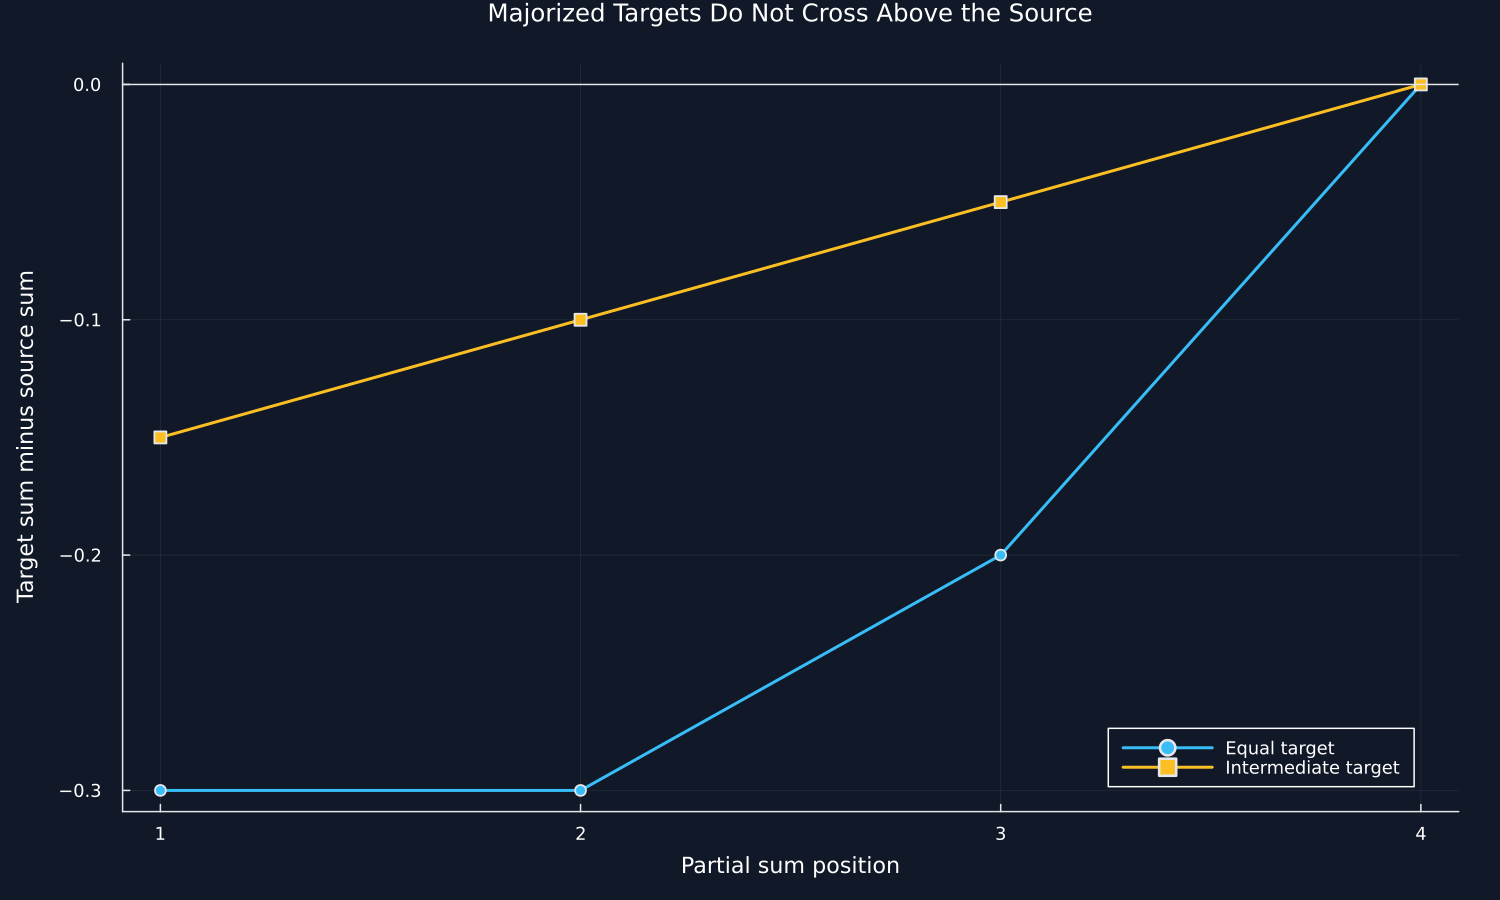

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("24_portfolio_majorization");
using CSV, Printf
using RiskLabAI.Optimization: birkhoff_von_neumann_decomposition,is_doubly_stochastic,is_majorized,majorization_matrix
violet = "#C084FC"
ordered(values) = sort(Float64.(values);rev=true)
partial_sums(values) = cumsum(ordered(values))
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter25-"*replace(name,"_"=>"-"))
function concentration_record(name,values)
    positive = values[values.>0]
    squared = sum(abs2,values)
    entropy = -sum(positive.*log.(positive))
    return (Vector=name,largest=maximum(values),squared=squared,fourth=sum(values.^4),effective=1/squared,entropy_effective=exp(entropy))
end
function concentration_table(vectors)
    frame = DataFrame([concentration_record(name,values) for (name,values) in vectors])
    rename!(frame,["Vector","Largest component","Squared sum","Fourth power sum","Effective count","Entropy effective count"])
    return frame
end
function matrix_table(matrix)
    return hcat(DataFrame("Matrix row"=>["Row "*string(i) for i in axes(matrix,1)]),DataFrame(matrix,["Column "*string(i) for i in axes(matrix,2)]))
end
function matrix_data(matrix)
    return hcat(DataFrame(row=collect(axes(matrix,1))),DataFrame(matrix,["x"*string(i) for i in axes(matrix,2)]))
end
function decomposition_data(weights,orders)
    return hcat(DataFrame(term=collect(eachindex(weights)),weight=weights),DataFrame(orders,["column_"*string(i) for i in axes(orders,2)]))
end
function restore_decomposition(weights,orders)
    identity = Matrix{Float64}(I,size(orders,2),size(orders,2))
    return sum(weight.*identity[orders[index,:],:] for (index,weight) in enumerate(weights))
end
vectors = ["Equal"=>[0.25,0.25,0.25,0.25],"Intermediate"=>[0.40,0.30,0.20,0.10],"Concentrated"=>[0.55,0.25,0.15,0.05]]
vector_map = Dict(vectors)
notation = DataFrame("Symbol"=>["x","y","x_[i]","k","D"],"Description"=>["Source vector whose concentration is the reference","Target vector being compared with the source","Component i after sorting x from largest to smallest","Proper partial sum position","Doubly stochastic matrix when y equals D times x"])
table(notation,"majorization_notation","Notation for finite vector majorization.")
vector_table = DataFrame("Vector"=>first.(vectors))
for index in 1:4
    vector_table[!,"Component "*string(index)] = [values[index] for (name,values) in vectors]
end
vector_table[!,"Total"] = [sum(values) for (name,values) in vectors]
table(vector_table,"example_vectors","Vectors with four components used in the exact examples.")
partial_table = DataFrame("Position"=>1:4)
for (name,values) in vectors
    partial_table[!,name] = partial_sums(values)
end
table(partial_table,"ordered_partial_sums_table","Ordered partial sums for the exact examples.")
save_data(partial_table,paths,"ordered_partial_sums")
relation_table = DataFrame([(Target=target_name,Source=source_name,relation=is_majorized(target,source)) for (target_name,target) in vectors for (source_name,source) in vectors])
rename!(relation_table,:relation=>"Target majorized by source")
table(relation_table,"pairwise_majorization","Pairwise majorization results for the exact examples.")
figure = plot(;title="Ordered Partial Sums Reveal Concentration",xlabel="Number of largest components",ylabel="Ordered partial sum",xticks=0:4,legend=:bottomright,size=(1000,600))
for ((name,values),color) in zip(vectors,[palette.green,palette.amber,palette.rose])
    plot!(figure,0:4,vcat(0.0,partial_sums(values));marker=:circle,markersize=4,color,label=name)
end
save_figure(figure,paths,"ordered_partial_sums")
gaps = DataFrame("Position"=>1:4,"Equal minus concentrated"=>partial_sums(vector_map["Equal"])-partial_sums(vector_map["Concentrated"]),"Intermediate minus concentrated"=>partial_sums(vector_map["Intermediate"])-partial_sums(vector_map["Concentrated"]))
save_data(gaps,paths,"partial_sum_gaps")
figure = plot(gaps.Position,gaps[!,"Equal minus concentrated"];marker=:circle,color=palette.cyan,label="Equal target",title="Majorized Targets Do Not Cross Above the Source",xlabel="Partial sum position",ylabel="Target sum minus source sum",xticks=1:4,legend=:bottomright,size=(1000,600))
plot!(figure,gaps.Position,gaps[!,"Intermediate minus concentrated"];marker=:square,color=palette.amber,label="Intermediate target")
hline!(figure,[0.0];color=palette.text,linewidth=1,label=false)
save_figure(figure,paths,"partial_sum_gaps")
@assert all(length(values)==4 for (name,values) in vectors)
@assert all(isapprox(sum(values),1) for (name,values) in vectors)
@assert nrow(relation_table)==9


## Convex Measures of Concentration

For a nonnegative portfolio weight vector $w$ with total one, the squared concentration and its reciprocal are

$$
H(w)=\sum_{i=1}^{n}w_i^2,
\qquad
N_{\mathrm{eff}}(w)=\frac{1}{H(w)}.
$$

Here, $w_i$ is the weight of asset $i$, $H(w)$ is the squared concentration, and $N_{\mathrm{eff}}(w)$ is the effective number of equally weighted positions. A larger $H(w)$ and a smaller $N_{\mathrm{eff}}(w)$ indicate greater concentration. These summaries do not record asset dependence or expected returns.

Row,Vector,Largest component,Squared sum,Fourth power sum,Effective count,Entropy effective count
,String,Float64,Float64,Float64,Float64,Float64
1,Equal,0.25,0.25,0.015625,4.0,4.0
2,Intermediate,0.4,0.3,0.0354,3.33333,3.59612
3,Concentrated,0.55,0.39,0.095925,2.5641,3.03357


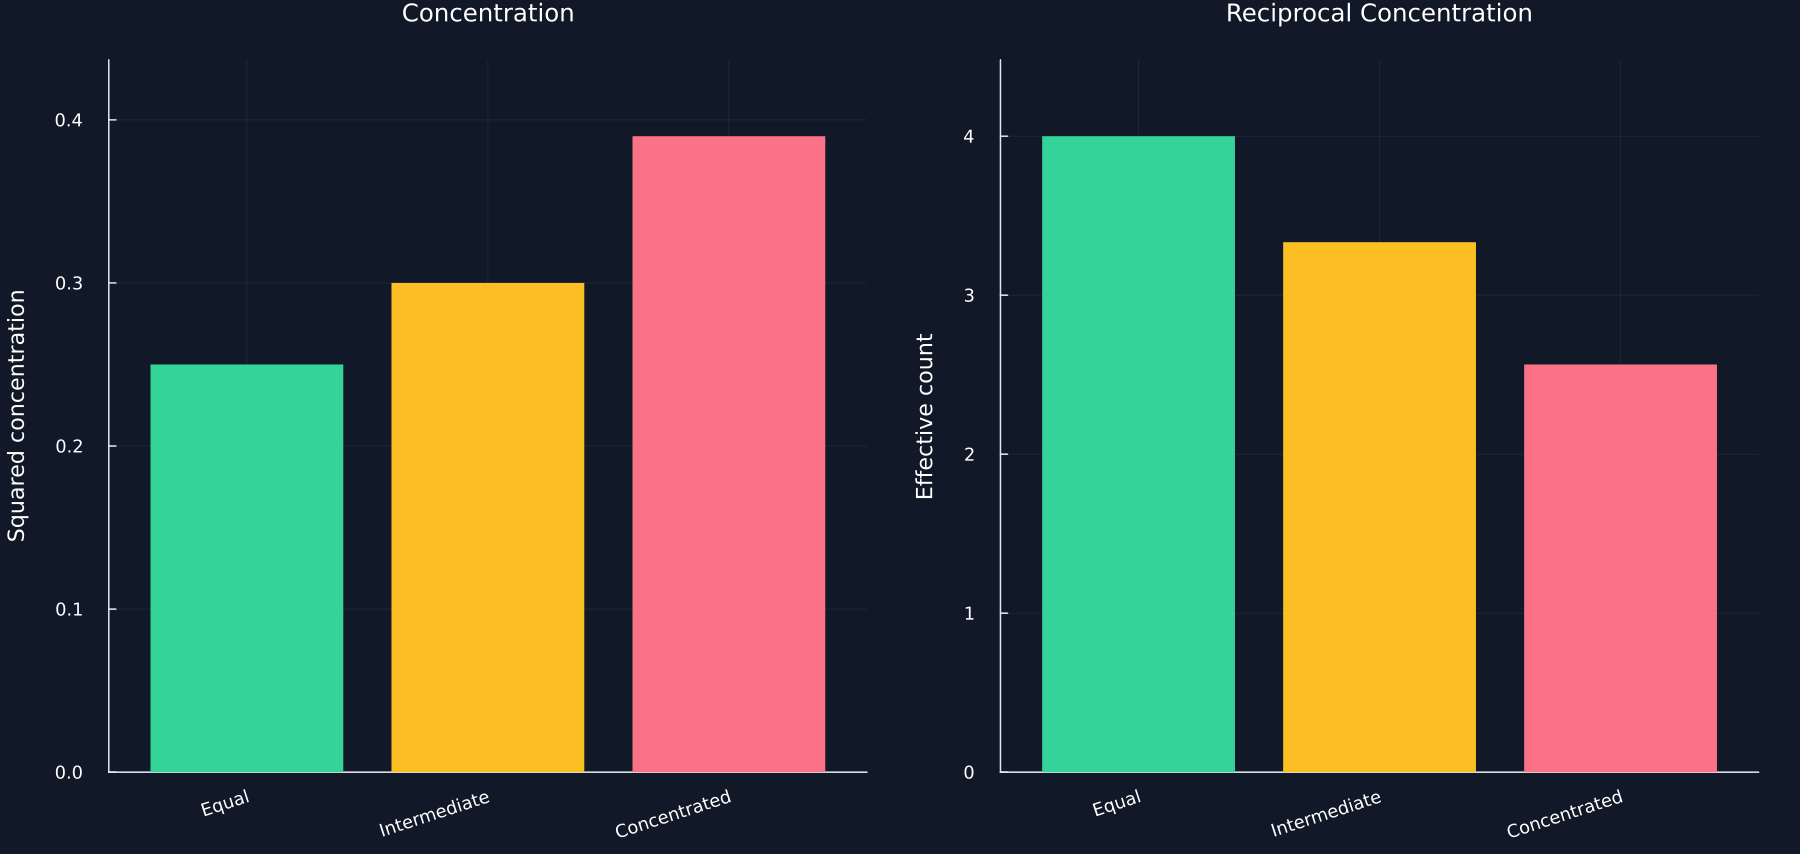

Row,Position,Vector A,Vector B,A minus B
,Int64,Float64,Float64,Float64
1,1,0.5,0.4,0.1
2,2,0.7,0.8,-0.1
3,3,0.9,0.9,0.0
4,4,1.0,1.0,0.0


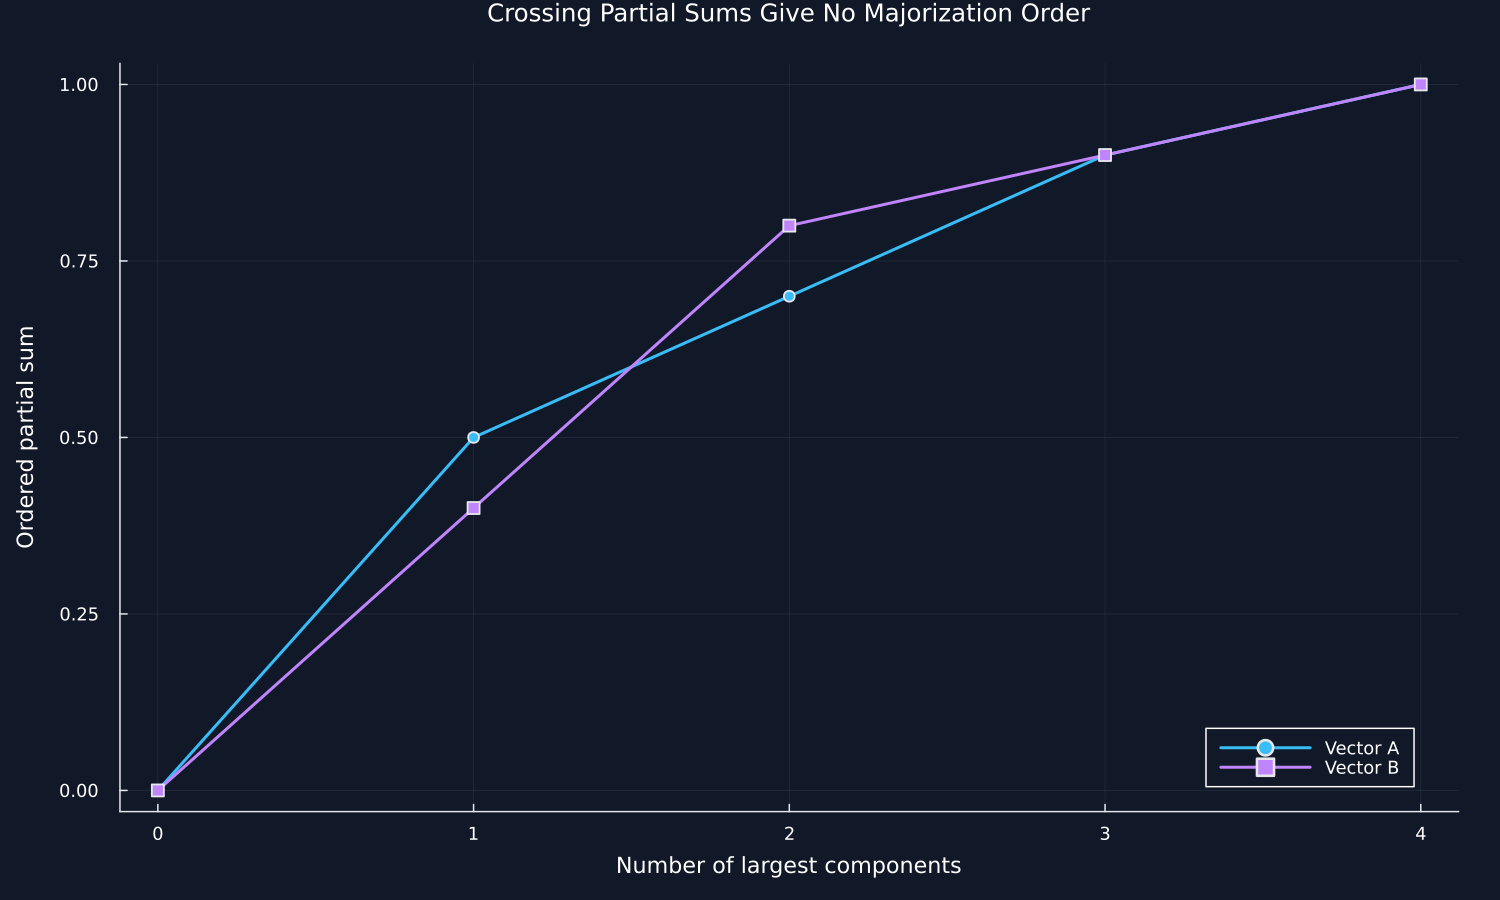

In [2]:
concentration = concentration_table(vectors)
table(concentration,"concentration_statistics","Convex concentration summaries for the exact examples.")
save_data(concentration,paths,"concentration_measures")
colors = [palette.green,palette.amber,palette.rose]
p1 = bar(1:3,concentration[!,"Squared sum"];color=colors,linealpha=0,xticks=(1:3,concentration.Vector),xrotation=18,title="Concentration",ylabel="Squared concentration",ylims=(0,1.12*maximum(concentration[!,"Squared sum"])),legend=false)
p2 = bar(1:3,concentration[!,"Effective count"];color=colors,linealpha=0,xticks=(1:3,concentration.Vector),xrotation=18,title="Reciprocal Concentration",ylabel="Effective count",ylims=(0,1.12*maximum(concentration[!,"Effective count"])),legend=false)
save_figure(plot(p1,p2;layout=(1,2),size=(1200,570)),paths,"concentration_measures")
incomparable_a,incomparable_b = [0.50,0.20,0.20,0.10],[0.40,0.40,0.10,0.10]
incomparable = DataFrame("Position"=>1:4,"Vector A"=>partial_sums(incomparable_a),"Vector B"=>partial_sums(incomparable_b),"A minus B"=>partial_sums(incomparable_a)-partial_sums(incomparable_b))
table(incomparable,"incomparable_pair","Crossing ordered partial sums for an incomparable pair.")
save_data(incomparable,paths,"incomparable_partial_sums")
figure = plot(0:4,vcat(0.0,partial_sums(incomparable_a));color=palette.cyan,marker=:circle,label="Vector A",xlabel="Number of largest components",ylabel="Ordered partial sum",title="Crossing Partial Sums Give No Majorization Order",xticks=0:4,legend=:bottomright,size=(1000,600))
plot!(figure,0:4,vcat(0.0,partial_sums(incomparable_b));color=violet,marker=:square,label="Vector B")
save_figure(figure,paths,"incomparable_partial_sums")


## Comparing signed-vector permutations

Majorization is defined for real vectors with equal totals, so components need not be positive. Sorting also makes the relation invariant to a relabeling of components. For the signed target $y=(-1,0,1)$ and source $x=(-2,0,2)$, the proper ordered partial sums of $y$ remain below those of $x$, while both totals equal zero.

In [3]:
signed_target,signed_source = [-1.0,0.0,1.0],[-2.0,0.0,2.0]
signed = DataFrame("Position"=>1:3,"Target ordered component"=>ordered(signed_target),"Source ordered component"=>ordered(signed_source),"Target partial sum"=>partial_sums(signed_target),"Source partial sum"=>partial_sums(signed_source),"Target majorized by source"=>fill(is_majorized(signed_target,signed_source),3))
table(signed,"signed_vector_checks","Ordered components and partial sums for a signed example.")
permutations = [[1,2,3,4],[4,3,2,1],[2,4,1,3]]
permutation_table = DataFrame([(Relabeling=index,Order=join(order," "),majorized=is_majorized(vector_map["Intermediate"][order],vector_map["Concentrated"]),squared=sum(abs2,vector_map["Intermediate"][order]),largest=maximum(vector_map["Intermediate"][order])) for (index,order) in enumerate(permutations)])
rename!(permutation_table,["Relabeling","Order","Majorized by concentrated","Squared sum","Largest component"])
table(permutation_table,"permutation_invariance_checks","Majorization and concentration after three component relabelings.")
@assert is_majorized(vector_map["Equal"],vector_map["Intermediate"])
@assert is_majorized(vector_map["Intermediate"],vector_map["Concentrated"])
@assert !is_majorized(incomparable_a,incomparable_b)
@assert !is_majorized(incomparable_b,incomparable_a)
@assert is_majorized(signed_target,signed_source)
@assert concentration[1,"Squared sum"]<concentration[3,"Squared sum"]
@assert all(permutation_table[!,"Majorized by concentrated"])
@assert isfile(joinpath(paths.figures,"ordered_partial_sums.pdf"))
@assert isfile(joinpath(paths.figures,"partial_sum_gaps.pdf"))
@assert isfile(joinpath(paths.figures,"concentration_measures.pdf"))
@assert isfile(joinpath(paths.figures,"incomparable_partial_sums.pdf"))


Row,Position,Target ordered component,Source ordered component,Target partial sum,Source partial sum,Target majorized by source
,Int64,Float64,Float64,Float64,Float64,Bool
1,1,1.0,2.0,1.0,2.0,true
2,2,0.0,0.0,1.0,2.0,true
3,3,-1.0,-2.0,0.0,0.0,true


Row,Relabeling,Order,Majorized by concentrated,Squared sum,Largest component
,Int64,String,Bool,Float64,Float64
1,1,1 2 3 4,true,0.3,0.4
2,2,4 3 2 1,true,0.3,0.4
3,3,2 4 1 3,true,0.3,0.4
